# Financial Transaction Fraud Detector
## Notebook 02 - Exploratory Data Analysis (EDA)

**Owner:** Mohamed Mohy  
**Role:** Exploratory Data Analysis (EDA)  
**Course / University:** AI in Cybersecurity, Sohag University  
**Date:** 2026-11-24

**Goal.** Measure and visualize how fraud behaves in the data: how rare it is, when it happens, how large it is, and which columns can be trusted.

**Inputs:** `data/processed/clean.parquet`

**Outputs:** `reports/data_facts.json`, `reports/figures/02_*.png`

Run the notebooks in order 01, 02, 03, 04a, 04b, 05; each one reads the files saved by the previous one.

## Setup
We load the clean file saved by notebook 01. Every number in this notebook is **measured** from the
data, not assumed, and all of them are saved to `reports/data_facts.json` for the slides and reports.

In [1]:
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import data, plotstyle

plotstyle.apply()
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

In [2]:
df = data.load_clean()
df["type"] = df["type"].astype(str)
df["hour"] = df["step"] % 24
scored = df[df["type"].isin(data.SCORED_TYPES)]
fraud = df[df["isFraud"] == 1]
normal_scored = scored[scored["isFraud"] == 0]
print(f"{len(df):,} transactions, {len(scored):,} of them TRANSFER or CASH_OUT")

6,362,620 transactions, 2,770,409 of them TRANSFER or CASH_OUT


## 1. How rare is fraud?

Fraud is a **needle in a haystack** problem. This rarity is the main reason why simple measures like
accuracy are misleading (see notebook 04b).

In [3]:
rate_all = df["isFraud"].mean()
rate_scored = scored["isFraud"].mean()
per_type = df.groupby("type")["isFraud"].agg(transactions="size", fraud="sum")
per_type["fraud_rate_pct"] = 100 * per_type["fraud"] / per_type["transactions"]
print(f"Overall fraud rate: {100 * rate_all:.3f}%  (about 1 in {1 / rate_all:,.0f} transactions)")
print(f"Fraud rate in TRANSFER + CASH_OUT: {100 * rate_scored:.3f}%")
per_type.sort_values("fraud_rate_pct", ascending=False)

Overall fraud rate: 0.129%  (about 1 in 775 transactions)
Fraud rate in TRANSFER + CASH_OUT: 0.296%


,transactions,fraud,fraud_rate_pct
type,,,
TRANSFER,532909,4097,0.77
CASH_OUT,2237500,4116,0.18
CASH_IN,1399284,0,0.00
DEBIT,41432,0,0.00
PAYMENT,2151495,0,0.00


## 2. Amounts: fraud vs normal

We compare the amount of fraud and normal transactions **within TRANSFER and CASH_OUT** (a fair comparison).
The x-axis is logarithmic because amounts range from a few units to tens of millions.

In [4]:
amt = scored.groupby("isFraud")["amount"].describe(percentiles=[0.5, 0.9])
amt.index = ["Normal", "Fraud"]
amt[["count", "mean", "50%", "90%", "max"]]

,count,mean,50%,90%,max
Normal,"2,762,196.00","314,115.50","171,034.46","540,837.92","92,445,516.64"
Fraud,"8,213.00","1,467,967.30","441,423.44","4,521,723.51","10,000,000.00"


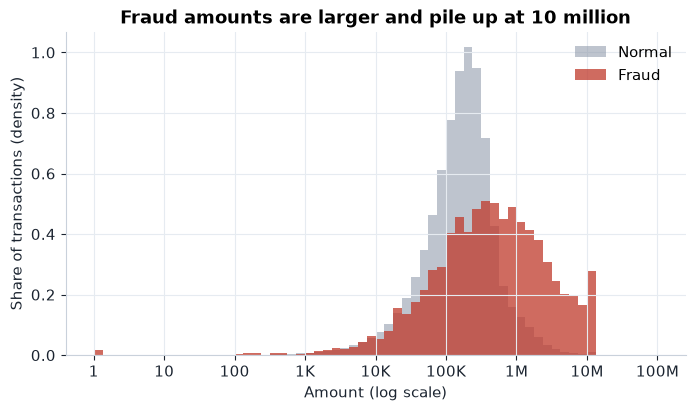

Largest fraud amount: 10,000,000; 287 fraud rows are exactly at this cap
Median fraud amount is 2.6x the median normal TRANSFER/CASH_OUT amount


In [5]:
bins = np.linspace(0, 8, 65)
fig, ax = plt.subplots()
ax.hist(np.log10(normal_scored["amount"].clip(lower=1)), bins=bins, density=True, alpha=0.55, color=plotstyle.GREY, label="Normal")
ax.hist(np.log10(fraud["amount"].clip(lower=1)), bins=bins, density=True, alpha=0.75, color=plotstyle.RED, label="Fraud")
ax.set_xticks(range(0, 9), ["1", "10", "100", "1K", "10K", "100K", "1M", "10M", "100M"])
ax.set_xlabel("Amount (log scale)")
ax.set_ylabel("Share of transactions (density)")
ax.set_title("Fraud amounts are larger and pile up at 10 million")
ax.legend()
plotstyle.save(fig, "02_amounts")
plt.show()

max_fraud = fraud["amount"].max()
at_cap = int((fraud["amount"] == max_fraud).sum())
median_ratio = fraud["amount"].median() / normal_scored["amount"].median()
print(f"Largest fraud amount: {max_fraud:,.0f}; {at_cap} fraud rows are exactly at this cap")
print(f"Median fraud amount is {median_ratio:.1f}x the median normal TRANSFER/CASH_OUT amount")

## 3. When does fraud happen?

`step` is one hour, so `step % 24` gives the hour of day. Normal customers sleep at night; in the
simulation, fraudsters do not. The **fraud rate** therefore jumps at night even though the number of
fraud cases per hour is roughly flat.

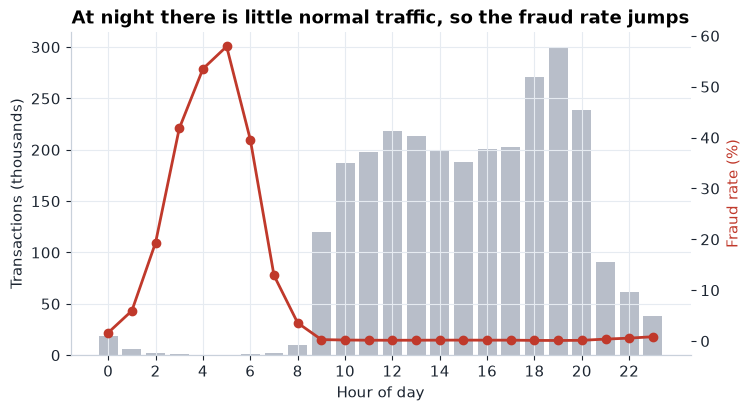

Share of fraud at night (00-05): 24.3%  vs normal: 0.9%
Fraud rate at night: 7.11%  vs day: 0.23%


In [6]:
by_hour = scored.groupby("hour")["isFraud"].agg(transactions="size", fraud="sum")
by_hour["fraud_rate_pct"] = 100 * by_hour["fraud"] / by_hour["transactions"]

fig, ax1 = plt.subplots()
ax1.bar(by_hour.index, by_hour["transactions"] / 1e3, color=plotstyle.GREY, alpha=0.6, label="All transactions (thousands)")
ax1.set_xlabel("Hour of day")
ax1.set_ylabel("Transactions (thousands)")
ax2 = ax1.twinx()
ax2.plot(by_hour.index, by_hour["fraud_rate_pct"], color=plotstyle.RED, marker="o", lw=2, label="Fraud rate (%)")
ax2.set_ylabel("Fraud rate (%)", color=plotstyle.RED)
ax2.grid(False)
ax1.set_title("At night there is little normal traffic, so the fraud rate jumps")
ax1.set_xticks(range(0, 24, 2))
plotstyle.save(fig, "02_fraud_by_hour")
plt.show()

night = scored["hour"] < 6
night_fraud_share = fraud["hour"].lt(6).mean()
night_normal_share = normal_scored["hour"].lt(6).mean()
night_rate = scored.loc[night, "isFraud"].mean()
day_rate = scored.loc[~night, "isFraud"].mean()
print(f"Share of fraud at night (00-05): {100 * night_fraud_share:.1f}%  vs normal: {100 * night_normal_share:.1f}%")
print(f"Fraud rate at night: {100 * night_rate:.2f}%  vs day: {100 * day_rate:.2f}%")

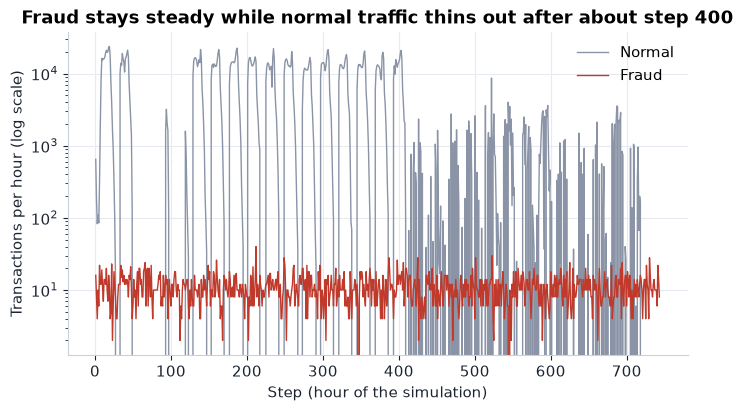

Fraud rate in steps 1-400: 0.18%  vs steps 401-743: 1.55%
This matters for the time-based split in notebook 04a: the latest hours have a much higher fraud rate.


In [7]:
by_step = scored.groupby("step")["isFraud"].agg(transactions="size", fraud="sum")
fig, ax = plt.subplots()
ax.plot(by_step.index, by_step["transactions"] - by_step["fraud"], color=plotstyle.GREY, lw=1, label="Normal")
ax.plot(by_step.index, by_step["fraud"], color=plotstyle.RED, lw=1, label="Fraud")
ax.set_yscale("log")
ax.set_xlabel("Step (hour of the simulation)")
ax.set_ylabel("Transactions per hour (log scale)")
ax.set_title("Fraud stays steady while normal traffic thins out after about step 400")
ax.legend()
plotstyle.save(fig, "02_over_time")
plt.show()

early = scored["step"] <= 400
late_rate = scored.loc[~early, "isFraud"].mean()
early_rate = scored.loc[early, "isFraud"].mean()
print(f"Fraud rate in steps 1-400: {100 * early_rate:.2f}%  vs steps 401-743: {100 * late_rate:.2f}%")
print("This matters for the time-based split in notebook 04a: the latest hours have a much higher fraud rate.")

## 4. The simulator's own rule: `isFlaggedFraud`

PaySim flags a transaction when it is a TRANSFER above 200,000 under certain conditions. How useful is that rule?

In [8]:
flagged = df[df["isFlaggedFraud"] == 1]
flag_caught = int(flagged["isFraud"].sum())
flag_recall = flag_caught / len(fraud)
print(f"Rows flagged by the rule: {len(flagged)}")
print(f"Of these, real fraud: {flag_caught}")
print(f"Share of all fraud the rule catches (recall): {100 * flag_recall:.2f}%")

Rows flagged by the rule: 16
Of these, real fraud: 16
Share of all fraud the rule catches (recall): 0.19%


## 5. Account IDs: who repeats?

`nameOrig` (sender) and `nameDest` (receiver) are IDs. Accounts starting with **M** are merchants.
If senders almost never repeat, we cannot build sender history. Receivers repeat a lot, which is
what makes **receiver history** (notebook 03) possible.

In [9]:
orig_unique = df["nameOrig"].nunique()
dest_unique = df["nameDest"].nunique()
merchant_dest_types = sorted(df.loc[df["nameDest"].str.startswith("M"), "type"].unique())
dest_counts = df["nameDest"].value_counts()
ids = pd.DataFrame({
    "unique accounts": [orig_unique, dest_unique],
    "rows per account (avg)": [len(df) / orig_unique, len(df) / dest_unique],
    "accounts seen more than once": [int((df["nameOrig"].value_counts() > 1).sum()), int((dest_counts > 1).sum())],
}, index=["nameOrig (sender)", "nameDest (receiver)"])
print("Merchant (M) receivers appear only in:", merchant_dest_types)
ids

Merchant (M) receivers appear only in: ['PAYMENT']


,unique accounts,rows per account (avg),accounts seen more than once
nameOrig (sender),6353307,1.00,9298
nameDest (receiver),2722362,2.34,459658


In [10]:
fraud_transfer_dest = set(fraud.loc[fraud["type"] == "TRANSFER", "nameDest"])
fraud_cashout_orig = set(fraud.loc[fraud["type"] == "CASH_OUT", "nameOrig"])
linked = len(fraud_transfer_dest & fraud_cashout_orig)
print(f"Fraud TRANSFER receivers that later appear as a fraud CASH_OUT sender: {linked}")
print("PaySim does not link the two steps of a fraud by account ID, so we cannot follow money chains directly.")

Fraud TRANSFER receivers that later appear as a fraud CASH_OUT sender: 0
PaySim does not link the two steps of a fraud by account ID, so we cannot follow money chains directly.


## 6. A warning about the balance columns

The dataset author explains that **fraudulent transactions were cancelled** in the simulation. Because of
that, the balance columns of fraud rows behave differently from normal rows for reasons that have nothing to
do with real fraud. We measure this: for each row we check whether the balances "add up":

- sender: `oldbalanceOrg - amount = newbalanceOrig`
- receiver: `oldbalanceDest + amount = newbalanceDest`

In [11]:
tol = 0.01
err_orig = (scored["oldbalanceOrg"] - scored["amount"] - scored["newbalanceOrig"]).abs() > tol
err_dest = (scored["oldbalanceDest"] + scored["amount"] - scored["newbalanceDest"]).abs() > tol
empties = (scored["amount"] - scored["oldbalanceOrg"]).abs() <= tol
dest_zero = (scored["oldbalanceDest"] == 0) & (scored["newbalanceDest"] == 0) & (scored["amount"] > 0)

bal = pd.DataFrame({
    "Sender balances do not add up": err_orig.groupby(scored["isFraud"]).mean(),
    "Receiver balances do not add up": err_dest.groupby(scored["isFraud"]).mean(),
    "Amount equals the whole sender balance": empties.groupby(scored["isFraud"]).mean(),
    "Receiver balance 0 before and after": dest_zero.groupby(scored["isFraud"]).mean(),
}).T * 100
bal.columns = ["Normal (%)", "Fraud (%)"]
bal

,Normal (%),Fraud (%)
Sender balances do not add up,90.51,0.55
Receiver balances do not add up,22.58,56.50
Amount equals the whole sender balance,0.00,97.82
Receiver balance 0 before and after,0.06,49.56


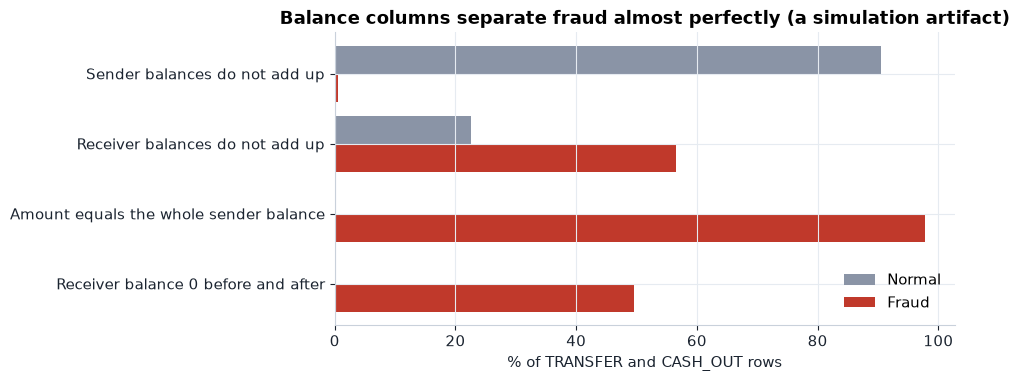

In [12]:
fig, ax = plt.subplots(figsize=(8, 3.8))
y = np.arange(len(bal))
ax.barh(y - 0.2, bal["Normal (%)"], height=0.4, color=plotstyle.GREY, label="Normal")
ax.barh(y + 0.2, bal["Fraud (%)"], height=0.4, color=plotstyle.RED, label="Fraud")
ax.set_yticks(y, bal.index)
ax.invert_yaxis()
ax.set_xlabel("% of TRANSFER and CASH_OUT rows")
ax.set_title("Balance columns separate fraud almost perfectly (a simulation artifact)")
ax.legend(loc="lower right")
plotstyle.save(fig, "02_balance_artifact")
plt.show()

**What this means.** The balance patterns separate fraud from normal transactions far too cleanly. Part of it is
real fraud behavior (a criminal who takes over an account tries to **empty it**), but part of it is an
**artifact** of how the simulator cancelled fraud (for example, receiver balances that never change).
A model that uses balances **after** the transaction will look almost perfect for the wrong reasons.
Notebook 04a therefore trains models with and without these columns and reports the difference honestly.

In [13]:
facts = {
    "rows_total": int(len(df)),
    "rows_transfer_cashout": int(len(scored)),
    "fraud_total": int(len(fraud)),
    "fraud_rate_pct": round(100 * rate_all, 4),
    "fraud_rate_scored_pct": round(100 * rate_scored, 4),
    "fraud_by_type": {t: int(v) for t, v in per_type["fraud"].items()},
    "fraud_rate_by_type_pct": {t: round(float(v), 4) for t, v in per_type["fraud_rate_pct"].items()},
    "steps": int(df["step"].nunique()),
    "max_fraud_amount": float(max_fraud),
    "fraud_rows_at_max_amount": at_cap,
    "median_amount_fraud": float(fraud["amount"].median()),
    "median_amount_normal_scored": float(normal_scored["amount"].median()),
    "night_share_fraud_pct": round(100 * night_fraud_share, 2),
    "night_share_normal_pct": round(100 * night_normal_share, 2),
    "fraud_rate_night_pct": round(100 * night_rate, 3),
    "fraud_rate_day_pct": round(100 * day_rate, 3),
    "fraud_rate_steps_1_400_pct": round(100 * early_rate, 3),
    "fraud_rate_steps_401_743_pct": round(100 * late_rate, 3),
    "flagged_rows": int(len(flagged)),
    "flagged_true_fraud": flag_caught,
    "flagged_recall_pct": round(100 * flag_recall, 3),
    "unique_senders": int(orig_unique),
    "unique_receivers": int(dest_unique),
    "fraud_chain_links_found": int(linked),
    "balance_checks_pct": {k: {"normal": round(float(v["Normal (%)"]), 2), "fraud": round(float(v["Fraud (%)"]), 2)}
                           for k, v in bal.iterrows()},
}
data.write_json(facts, data.REPORTS / "data_facts.json")
print("Saved reports/data_facts.json")

Saved reports/data_facts.json


In [14]:
b = facts["balance_checks_pct"]
data.write_findings("02_eda", [
    f"Fraud is very rare: {facts['fraud_rate_pct']:.2f}% of all transactions (about 1 in {round(1 / rate_all):,}), and {facts['fraud_rate_scored_pct']:.2f}% within TRANSFER and CASH_OUT.",
    f"Fraud amounts are larger: the median fraud is {median_ratio:.1f}x the median normal transfer, and {at_cap} frauds sit exactly at the {max_fraud:,.0f} cap.",
    f"Fraud does not sleep: {facts['night_share_fraud_pct']:.0f}% of fraud happens between 00:00 and 05:59 versus {facts['night_share_normal_pct']:.0f}% of normal traffic, so the night-time fraud rate is {facts['fraud_rate_night_pct']:.1f}% versus {facts['fraud_rate_day_pct']:.2f}% by day.",
    f"Normal traffic thins out late in the month, so the fraud rate rises from {facts['fraud_rate_steps_1_400_pct']:.2f}% (steps 1-400) to {facts['fraud_rate_steps_401_743_pct']:.2f}% (steps 401-743).",
    f"The simulator rule isFlaggedFraud flags only {facts['flagged_rows']} rows and catches {facts['flagged_recall_pct']:.2f}% of fraud.",
    f"Balance columns separate the classes too cleanly to trust: {b['Amount equals the whole sender balance']['fraud']:.0f}% of frauds move exactly the whole sender balance (normal: {b['Amount equals the whole sender balance']['normal']:.1f}%), sender balances fail to add up for {b['Sender balances do not add up']['normal']:.0f}% of normal rows but only {b['Sender balances do not add up']['fraud']:.1f}% of frauds, and the receiver balance stays 0 for {b['Receiver balance 0 before and after']['fraud']:.0f}% of frauds.",
])
print("Findings saved.")

Findings saved.


## Key findings

- Fraud is very rare: 0.13% of all transactions (about 1 in 775), and 0.30% within TRANSFER and CASH_OUT.
- Fraud amounts are larger: the median fraud is 2.6x the median normal transfer, and 287 frauds sit exactly at the 10,000,000 cap.
- Fraud does not sleep: 24% of fraud happens between 00:00 and 05:59 versus 1% of normal traffic, so the night-time fraud rate is 7.1% versus 0.23% by day.
- Normal traffic thins out late in the month, so the fraud rate rises from 0.18% (steps 1-400) to 1.55% (steps 401-743).
- The simulator rule isFlaggedFraud flags only 16 rows and catches 0.20% of fraud.
- Balance columns separate the classes too cleanly to trust: 98% of frauds move exactly the whole sender balance (normal: 0.0%), sender balances fail to add up for 91% of normal rows but only 0.6% of frauds, and the receiver balance stays 0 for 50% of frauds.